In [3]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares

plt.rcParams["font.family"] = "Hiragino Sans"
PROJECT_DIR = Path.home() / "applied_programming_ii" / "08"
DATA_DIR = Path.home() / "applied_programming_ii" / "data"
FIGURE_DIR = PROJECT_DIR / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
print("ダムデータの有無:", (DATA_DIR / "dam_urayama_daily.csv").exists())
print("降水量データの有無:", (DATA_DIR / "precipitation_chichibu_daily.csv").exists())

ダムデータの有無: True
降水量データの有無: False


In [4]:
dam = pd.read_csv(DATA_DIR / "dam_urayama_daily.csv", parse_dates=["date"])
rain = pd.read_csv(DATA_DIR / "precipitation_chichibu_daily.csv", parse_dates=["date"])

In [5]:
dam.head()

,date,water_level_m,inflow_m3s,outflow_m3s
0,2015-01-01,380.37,0.72,0.72
1,2015-01-02,380.37,0.72,0.72
2,2015-01-03,380.37,0.72,0.72
3,2015-01-04,380.37,0.72,0.72
4,2015-01-05,380.37,0.72,0.72


In [6]:
rain.head()

,date,precipitation_mm
0,2019-01-01,0.0
1,2019-01-02,0.0
2,2019-01-03,0.0
3,2019-01-04,0.0
4,2019-01-05,0.0


In [7]:
dam.describe()

,date,water_level_m,inflow_m3s,outflow_m3s
count,3287,3287.000000,3287.000000,3287.000000
mean,2019-07-01 23:59:59.999999744,375.547073,1.947286,1.982187
min,2015-01-01 00:00:00,356.010000,0.000000,0.710000
25%,2017-04-01 12:00:00,371.950000,0.730000,0.730000
50%,2019-07-02 00:00:00,375.270000,1.060000,0.740000
75%,2021-09-30 12:00:00,377.345000,1.870000,2.210000
max,2023-12-31 00:00:00,393.070000,201.110000,126.620000
std,NaN,5.605926,4.940315,3.719681


In [8]:
year = 2019
dam_year = dam[dam["date"].dt.year == year].reset_index(drop=True)
rain_year = rain[rain["date"].dt.year == year].reset_index(drop=True)
data = pd.merge(dam_year, rain_year, on="date", how="inner")

In [9]:
print("期間:", data["date"].min().date(), "〜", data["date"].max().date())
print("行数:", len(data))
print("欠損値の数:")
print(data.isna().sum().to_string())
intervals = data["date"].diff().dt.days.dropna()
print("日付の間隔 [日]:", sorted(intervals.unique().tolist()))

期間: 2019-01-01 〜 2019-12-31
行数: 365
欠損値の数:
date                0
water_level_m       0
inflow_m3s          0
outflow_m3s         0
precipitation_mm    0
日付の間隔 [日]: [1.0]


In [10]:
SECONDS_PER_DAY = 24 * 60 * 60

def m3s_to_1000m3_per_day(flow_m3s):
    return flow_m3s * SECONDS_PER_DAY / 1000

t_data = np.arange(len(data), dtype=float)  # 時刻 [日]（1月1日を0とする）
rain_obs = data["precipitation_mm"].values  # 降水強度 [mm/日]（日降水量を1日で割った値）
qin_obs = m3s_to_1000m3_per_day(data["inflow_m3s"].values)  # 観測流入量 [千m^3/日]

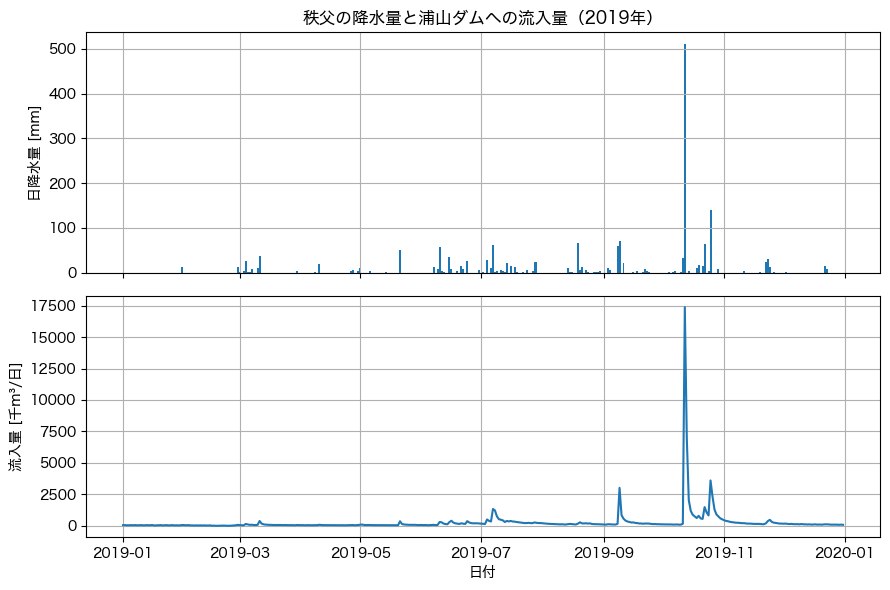

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
axes[0].bar(data["date"], rain_obs, color="tab:blue", width=1.0)
axes[0].set_ylabel("日降水量 [mm]")
axes[0].set_title(f"秩父の降水量と浦山ダムへの流入量（{year}年）")
axes[1].plot(data["date"], qin_obs, color="tab:blue")
axes[1].set_ylabel("流入量 [千m³/日]")
axes[1].set_xlabel("日付")
for ax in axes:
    ax.grid(True)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "rain_inflow_2019.png", dpi=150)
plt.show()

In [12]:
AREA_KM2 = 51.6  # 集水面積 [km^2]
rain_volume = AREA_KM2 * rain_obs  # 流域への降水の水量 [千m^3/日]
print(f"年降水量: {rain_obs.sum():.1f} mm")
print(f"降水量から換算した年水量: {rain_volume.sum():.1f} 千m^3")
print(f"観測流入量の年水量: {qin_obs.sum():.1f} 千m^3")

年降水量: 1865.5 mm
降水量から換算した年水量: 96259.8 千m^3
観測流入量の年水量: 96083.7 千m^3


In [13]:
def tank_rhs(t, S, t_data, rain_data, c, k):
    rain_input = c * AREA_KM2 * np.interp(t, t_data, rain_data)
    return rain_input - k * S

In [14]:
def simulate_tank(theta, t_data, rain_data, q0):
    c, k = theta
    S0 = q0 / k
    sol = solve_ivp(
        tank_rhs, (t_data[0], t_data[-1]), [S0],
        t_eval=t_data, args=(t_data, rain_data, c, k),
        max_step=0.25, rtol=1e-7, atol=1e-5,
    )
    return k * sol.y[0]

In [15]:
t_demo = np.arange(31, dtype=float)  # 時刻 [日]
rain_demo = np.zeros(len(t_demo))  # 降水強度 [mm/日]
q0_demo = 100.0  # 初日の流出量 [千m^3/日]
k_demo = 0.2  # 流出係数 [1/日]
q_demo = simulate_tank((0.7, k_demo), t_demo, rain_demo, q0_demo)
print(f"時定数: {1 / k_demo:.1f} 日")
print(f"5日後の流出量: {q_demo[5]:.2f} 千m^3/日")

時定数: 5.0 日
5日後の流出量: 36.79 千m^3/日


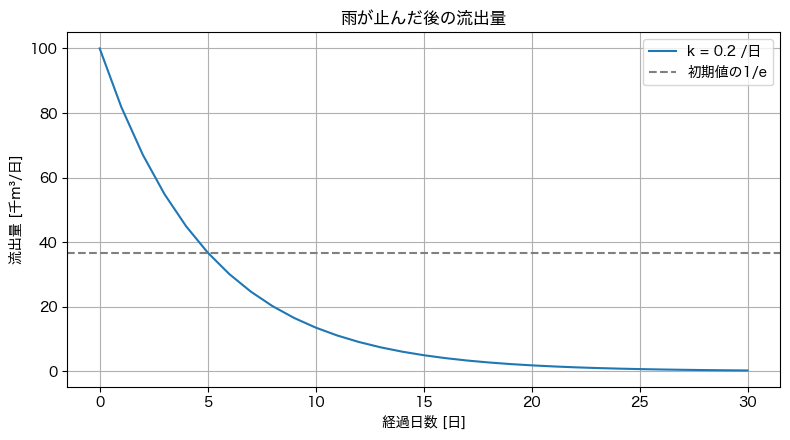

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(t_demo, q_demo, color="tab:blue", label=f"k = {k_demo:.1f} /日")
ax.axhline(q0_demo / np.e, color="gray", linestyle="--", label="初期値の1/e")
ax.set_title("雨が止んだ後の流出量")
ax.set_xlabel("経過日数 [日]")
ax.set_ylabel("流出量 [千m³/日]")
ax.grid(True)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "tank_recession.png", dpi=150)
plt.show()

# 演習1

In [17]:
q_slow = simulate_tank((0.7, 0.1), t_demo, rain_demo, q0_demo)
q_fast = simulate_tank((0.7, 0.5), t_demo, rain_demo, q0_demo)

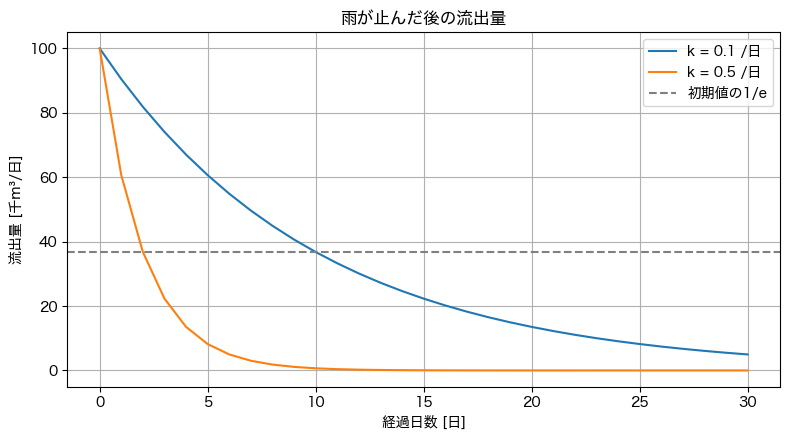

In [18]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(t_demo, q_slow, color="tab:blue", label="k = 0.1 /日")
ax.plot(t_demo, q_fast, color="tab:orange", label="k = 0.5 /日")
ax.axhline(q0_demo / np.e, color="gray", linestyle="--", label="初期値の1/e")
ax.set_title("雨が止んだ後の流出量")
ax.set_xlabel("経過日数 [日]")
ax.set_ylabel("流出量 [千m³/日]")
ax.grid(True)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "exercise1_recession.png", dpi=150)
plt.show()

In [19]:
def residuals_tank(theta, t_data, rain_data, qin_data, fit_mask):
    q_model = simulate_tank(theta, t_data, rain_data, qin_data[0])
    return (q_model - qin_data)[fit_mask]

In [20]:
fit_mask = np.ones(len(t_data), dtype=bool)
theta_initial = [0.7, 0.3]  # c，k [1/日]
bounds_tank = ([0.0, 0.001], [1.0, 5.0])

In [21]:
result_tank = least_squares(
    residuals_tank, theta_initial,
    args=(t_data, rain_obs, qin_obs, fit_mask),
    bounds=bounds_tank, diff_step=0.01,
)
c_hat, k_hat = result_tank.x
q_tank = simulate_tank(result_tank.x, t_data, rain_obs, qin_obs[0])
residual_tank = q_tank - qin_obs
rmse_tank = np.sqrt(np.mean(residual_tank[fit_mask] ** 2))

In [22]:
print("停止結果:", result_tank.success, result_tank.message)
print(f"c = {c_hat:.3f}，k = {k_hat:.3f} /日，時定数 = {1 / k_hat:.3f} 日")
print(f"2019年の当てはまりのRMSE: {rmse_tank:.1f} 千m^3/日")

停止結果: True `xtol` termination condition is satisfied.
c = 0.867，k = 2.815 /日，時定数 = 0.355 日
2019年の当てはまりのRMSE: 309.0 千m^3/日


In [23]:
theta_reference = result_tank.x.copy()

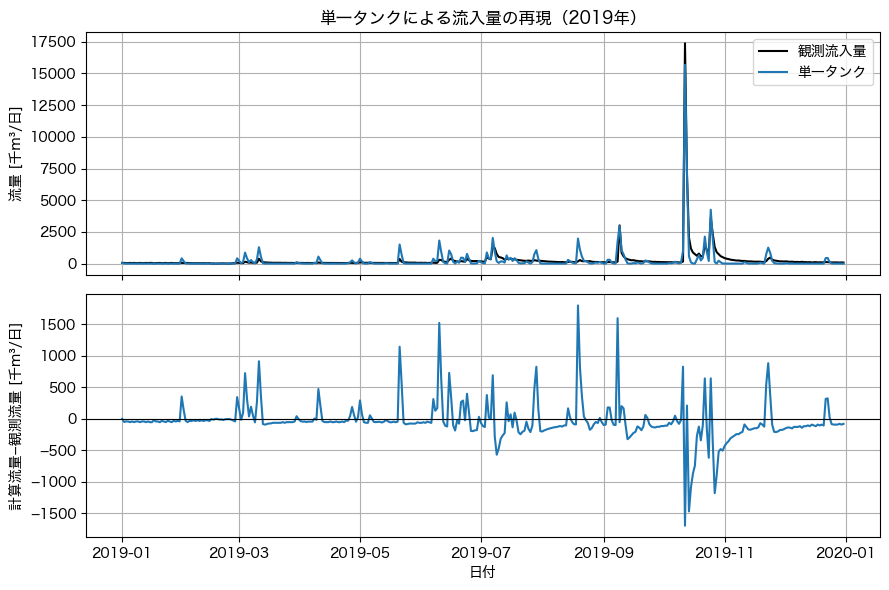

In [24]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
axes[0].plot(data["date"], qin_obs, color="black", label="観測流入量")
axes[0].plot(data["date"], q_tank, color="tab:blue", label="単一タンク")
axes[0].set_title(f"単一タンクによる流入量の再現（{year}年）")
axes[0].set_ylabel("流量 [千m³/日]")
axes[0].legend()
axes[1].plot(data["date"], residual_tank, color="tab:blue")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_ylabel("計算流量−観測流量 [千m³/日]")
axes[1].set_xlabel("日付")
for ax in axes:
    ax.grid(True)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "single_tank_2019.png", dpi=150)
plt.show()

In [25]:
train_mask = data["date"] <= "2019-09-30"
valid_mask = data["date"] >= "2019-10-01"
fit_mask = train_mask
result_tank = least_squares(
    residuals_tank, theta_initial,
    args=(t_data, rain_obs, qin_obs, fit_mask),
    bounds=bounds_tank, diff_step=0.01,
)
c_hat, k_hat = result_tank.x
q_tank = simulate_tank(result_tank.x, t_data, rain_obs, qin_obs[0])
residual_tank = q_tank - qin_obs
rmse_train = np.sqrt(np.mean(residual_tank[train_mask] ** 2))
rmse_valid = np.sqrt(np.mean(residual_tank[valid_mask] ** 2))

In [26]:
print(f"c = {c_hat:.3f}，k = {k_hat:.3f} /日")
print(f"訓練期間のRMSE: {rmse_train:.1f} 千m^3/日")
print(f"検証期間のRMSE: {rmse_valid:.1f} 千m^3/日")

c = 0.619，k = 0.701 /日
訓練期間のRMSE: 161.5 千m^3/日
検証期間のRMSE: 1336.0 千m^3/日


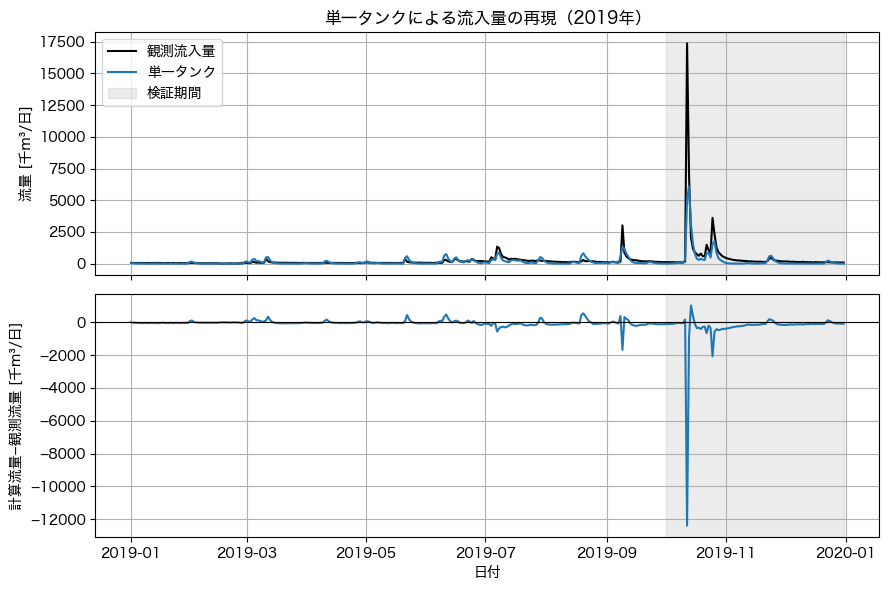

In [27]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
axes[0].plot(data["date"], qin_obs, color="black", label="観測流入量")
axes[0].plot(data["date"], q_tank, color="tab:blue", label="単一タンク")
axes[0].set_title(f"単一タンクによる流入量の再現（{year}年）")
axes[0].set_ylabel("流量 [千m³/日]")
axes[0].axvspan(data["date"][valid_mask].min(), data["date"].max(), color="gray", alpha=0.15, label="検証期間")
axes[0].legend()
axes[1].plot(data["date"], residual_tank, color="tab:blue")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].axvspan(data["date"][valid_mask].min(), data["date"].max(), color="gray", alpha=0.15)
axes[1].set_ylabel("計算流量−観測流量 [千m³/日]")
axes[1].set_xlabel("日付")
for ax in axes:
    ax.grid(True)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "exercise2_validation.png", dpi=150)
plt.show()